# Exercise 4 — Does a Second Hidden Layer Help?

Same data, learning rate and epoch budget as Exercise 3; the only change is depth.
Both networks are trained from three initialization seeds and averaged.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from mlp import MLP

%matplotlib inline

FIG_DIR = Path("..") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=1500, n_features=4, n_informative=4,
                           n_redundant=0, n_repeated=0, n_classes=3,
                           n_clusters_per_class=2, class_sep=1.0,
                           random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (1200, 4) | test: (300, 4)


In [3]:
LR, EPOCHS = 0.5, 2000
SEEDS = [42, 43, 44]
ARCHS = {"Ex. 3 (1 hidden)": [4, 16, 3], "Ex. 4 (2 hidden)": [4, 16, 16, 3]}

results = {name: {"loss": [], "acc": [], "curves": []} for name in ARCHS}
for name, arch in ARCHS.items():
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        model = MLP(arch, rng, output="softmax")
        losses = model.fit(X_train, y_train, epochs=EPOCHS, lr=LR)
        acc = model.accuracy(X_test, y_test)
        results[name]["loss"].append(losses[-1])
        results[name]["acc"].append(acc)
        results[name]["curves"].append(losses)
        print(f"{name}  seed {seed}: final train loss = {losses[-1]:.4f}, test acc = {acc:.4f}")
    results[name]["params"] = model.n_params()

Ex. 3 (1 hidden)  seed 42: final train loss = 0.2597, test acc = 0.8567


Ex. 3 (1 hidden)  seed 43: final train loss = 0.2636, test acc = 0.8367


Ex. 3 (1 hidden)  seed 44: final train loss = 0.2617, test acc = 0.8533


Ex. 4 (2 hidden)  seed 42: final train loss = 0.1680, test acc = 0.8533


Ex. 4 (2 hidden)  seed 43: final train loss = 0.1702, test acc = 0.8467


Ex. 4 (2 hidden)  seed 44: final train loss = 0.1800, test acc = 0.8567


In [4]:
print(f"{'model':<18}{'arch':<16}{'params':>7}{'train loss':>12}{'test acc':>10}")
for name, arch in ARCHS.items():
    r = results[name]
    print(f"{name:<18}{str(arch):<16}{r['params']:>7}"
          f"{np.mean(r['loss']):>12.4f}{np.mean(r['acc']):>10.4f}")

diff = np.mean(results["Ex. 4 (2 hidden)"]["acc"]) - np.mean(results["Ex. 3 (1 hidden)"]["acc"])
print(f"\nmean accuracy difference (Ex. 4 - Ex. 3) = {diff:+.4f}")

model             arch             params  train loss  test acc
Ex. 3 (1 hidden)  [4, 16, 3]          131      0.2617    0.8489
Ex. 4 (2 hidden)  [4, 16, 16, 3]      403      0.1727    0.8522

mean accuracy difference (Ex. 4 - Ex. 3) = +0.0033


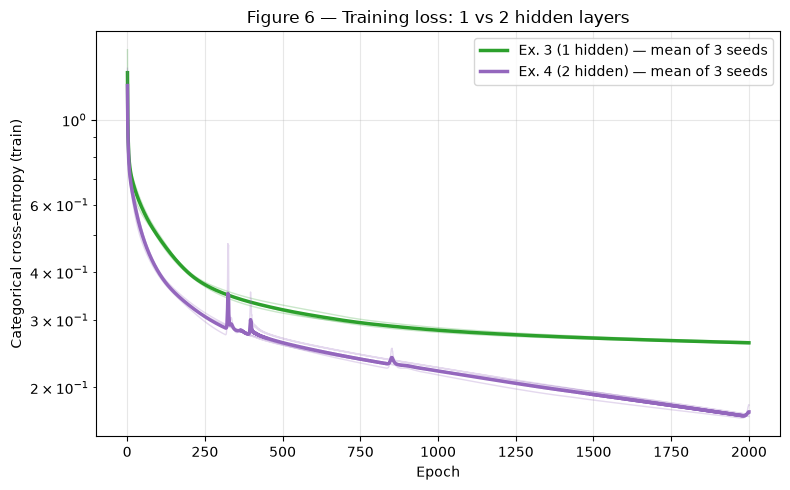

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = {"Ex. 3 (1 hidden)": "#2ca02c", "Ex. 4 (2 hidden)": "#9467bd"}
for name in ARCHS:
    curves = np.array(results[name]["curves"])
    for c in curves:
        ax.plot(range(1, EPOCHS + 1), c, color=colors[name], alpha=0.25, lw=1)
    ax.plot(range(1, EPOCHS + 1), curves.mean(axis=0), color=colors[name],
            lw=2.5, label=f"{name} — mean of {len(SEEDS)} seeds")
ax.set_title("Figure 6 — Training loss: 1 vs 2 hidden layers")
ax.set_xlabel("Epoch")
ax.set_ylabel("Categorical cross-entropy (train)")
ax.set_yscale("log")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_depth_loss.png", dpi=150)
plt.show()